# SUNS – Zadanie č. 1: kompletný kód

Tento notebook obsahuje celý kód potrebný na načítanie dát, čistenie, EDA, logistickú regresiu a neurónové siete. Nepotrebuje importovať vlastné moduly z priečinka `src`.

In [1]:
# Práca s cestami, kópiami váh modelu a reprodukovateľnosťou.
from pathlib import Path
import copy
import random

# Knižnice pre dáta, grafy, klasický model a neurónovú sieť.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch import nn

# Vyhľadáme koreň projektu nezávisle od priečinka, z ktorého sa notebook spustí.
PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / "data" / "online_shoppers.csv").is_file():
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise RuntimeError("Nenašiel sa koreň projektu s dátovým súborom.")
    PROJECT_ROOT = PROJECT_ROOT.parent

# Centrálne cesty k vstupným dátam a výstupom.
DATA_PATH = PROJECT_ROOT / "data" / "online_shoppers.csv"
PROCESSED_DATA_PATH = PROJECT_ROOT / "data" / "processed" / "online_shoppers_clean.csv"
FIGURES_DIR = PROJECT_ROOT / "results" / "figures"
TABLES_DIR = PROJECT_ROOT / "results" / "tables"

# Jeden seed umožní zopakovať delenie dát aj učenie siete s rovnakými výsledkami.
SEED = 2026
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

## Pomocné funkcie

In [2]:
# Stĺpce, ktorých hodnoty majú prirodzené významové obmedzenia.
DURATION_COLUMNS = [
    "Administrative_Duration",
    "Informational_Duration",
    "ProductRelated_Duration",
]
PAGE_COUNT_COLUMNS = ["Administrative", "Informational", "ProductRelated"]
BOUNDED_COLUMNS = ["BounceRates", "ExitRates", "SpecialDay"]

def load_data(path=DATA_PATH):
    """Načíta CSV dataset a zrozumiteľne ohlási chýbajúci súbor."""
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"Nenašiel sa dataset: {path}")
    return pd.read_csv(path)

def inspect_data(dataframe):
    """Vypíše základnú štruktúru, chýbajúce hodnoty a rozdelenie cieľa."""
    print("Shape:", dataframe.shape)
    print()
    print("Columns:", dataframe.columns.tolist())
    print()
    print("Data types:")
    display(dataframe.dtypes)
    print("Missing values:")
    display(dataframe.isna().sum())
    print("Target distribution:")
    display(dataframe["Revenue"].value_counts(dropna=False))
    print("First rows:")
    display(dataframe.head())
    print("Numerical statistics:")
    display(dataframe.describe().T)

def find_invalid_rows(dataframe):
    """Vráti masku riadkov s hodnotami, ktoré porušujú význam atribútov."""
    invalid_mask = pd.Series(False, index=dataframe.index)

    # Počty navštívených stránok a časy nemôžu byť záporné.
    for column in DURATION_COLUMNS + PAGE_COUNT_COLUMNS:
        invalid_mask |= dataframe[column] < 0

    # Mierové atribúty sú definované len na uzavretom intervale od 0 do 1.
    for column in BOUNDED_COLUMNS:
        invalid_mask |= (dataframe[column] < 0) | (dataframe[column] > 1)
    return invalid_mask

def clean_data(dataframe):
    """Vyčistí dáta bez odstraňovania platných, ale dlhých návštev."""
    cleaned = dataframe.copy()

    # Najprv odstránime iba semanticky neplatné hodnoty.
    invalid_mask = find_invalid_rows(cleaned)
    print(f"Invalid rows removed: {int(invalid_mask.sum())}")
    cleaned = cleaned.loc[~invalid_mask].copy()

    # Identifikátor nemá prediktívny význam; duration má priveľa chýbajúcich hodnôt.
    cleaned = cleaned.drop(columns=["SessionID", "Informational_Duration"])

    # Chýbajúce trvanie produktových stránok tvorí malý podiel dát a odstránime ho cielene.
    missing_duration_count = int(cleaned["ProductRelated_Duration"].isna().sum())
    cleaned = cleaned.dropna(subset=["ProductRelated_Duration"]).copy()
    print(f"Rows removed due to missing ProductRelated_Duration: {missing_duration_count}")

    # Informáciu o chýbajúcom type návštevníka ponecháme ako samostatnú kategóriu.
    cleaned["VisitorType"] = cleaned["VisitorType"].fillna("Unknown")
    return cleaned.reset_index(drop=True)

def save_clean_data(dataframe, path=PROCESSED_DATA_PATH):
    """Uloží očistený dataset; cieľový priečinok vytvorí, ak ešte neexistuje."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    dataframe.to_csv(path, index=False)
    print(f"Cleaned dataset saved to: {path}")

In [3]:
def setup_plot_style():
    """Nastaví spoločný vzhľad všetkých grafov v notebooku."""
    sns.set_theme(style="whitegrid", palette="deep")
    plt.rcParams["figure.figsize"] = (10, 6)
    plt.rcParams["figure.dpi"] = 120
    plt.rcParams["axes.titlesize"] = 14
    plt.rcParams["axes.labelsize"] = 11

def save_figure(filename):
    """Uloží aktuálny graf do results/figures a uvoľní jeho pamäť."""
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    output_path = FIGURES_DIR / filename
    plt.tight_layout()
    plt.savefig(output_path, bbox_inches="tight")
    plt.close()
    print(f"Figure saved to: {output_path}")

def print_grouped_revenue_rate(dataframe, group_column):
    """Zhrnie počet sessions, nákupov a mieru nákupu podľa zvoleného stĺpca."""
    summary = (
        dataframe.groupby(group_column, dropna=False)["Revenue"]
        .agg(sessions="count", purchases="sum", purchase_rate="mean")
        .sort_values("purchase_rate", ascending=False)
    )
    # Priemer logickej premennej predstavuje podiel; pre prezentáciu ho prevedieme na percentá.
    summary["purchase_rate"] *= 100
    display(summary.round(2))
    return summary

def plot_purchase_rate_by_visitor_type(dataframe):
    """Vytvorí tabuľku a graf miery nákupu podľa typu návštevníka."""
    summary = (
        dataframe.groupby("VisitorType", dropna=False)["Revenue"]
        .agg(sessions="count", purchases="sum", purchase_rate="mean")
        .reset_index()
        .sort_values("purchase_rate", ascending=False)
        .reset_index(drop=True)
    )
    summary["purchase_rate"] *= 100

    # Tabuľku uložíme aj samostatne, aby bola dostupná mimo notebooku.
    TABLES_DIR.mkdir(parents=True, exist_ok=True)
    summary.to_csv(TABLES_DIR / "eda_purchase_rate_by_visitor_type.csv", index=False)

    fig, ax = plt.subplots(figsize=(10, 6))
    sns.barplot(data=summary, x="VisitorType", y="purchase_rate",
                color="steelblue", errorbar=None, ax=ax)

    # Červená čiara ukazuje celkovú mieru nákupu naprieč všetkými sessions.
    overall_rate = dataframe["Revenue"].mean() * 100
    ax.axhline(overall_rate, color="darkred", linestyle="--",
               label=f"Celková miera nákupu: {overall_rate:.2f} %")
    ax.bar_label(
        ax.containers[0],
        labels=[f"{row.purchase_rate:.2f} %" + chr(10) + f"(n={row.sessions:,})"
                for row in summary.itertuples()],
        padding=5,
    )
    ax.set(title="Miera dokončenia nákupu podľa typu návštevníka",
           xlabel="Typ návštevníka", ylabel="Podiel sessions s nákupom (%)")
    ax.set_ylim(0, max(summary["purchase_rate"].max(), overall_rate) * 1.3)
    ax.legend(loc="upper right")
    save_figure("eda_purchase_rate_by_visitor_type.png")
    return summary

def plot_bounce_vs_exit_rates(dataframe):
    """Vypočíta korelácie a vykreslí vzťah BounceRates a ExitRates."""
    data = dataframe[["BounceRates", "ExitRates"]].dropna()

    # Pearson meria lineárnu, Spearman poradovú monotónnu závislosť.
    pearson = data["BounceRates"].corr(data["ExitRates"], method="pearson")
    spearman = data["BounceRates"].corr(data["ExitRates"], method="spearman")
    summary = pd.DataFrame({"relationship": ["BounceRates vs ExitRates"],
                            "sessions": [len(data)],
                            "pearson_correlation": [pearson],
                            "spearman_correlation": [spearman]})
    TABLES_DIR.mkdir(parents=True, exist_ok=True)
    summary.to_csv(TABLES_DIR / "eda_bounce_vs_exit_rates.csv", index=False)

    fig, ax = plt.subplots(figsize=(9, 6))
    # Priehľadnosť zlepší čitateľnosť v miestach s vysokou hustotou bodov.
    ax.scatter(data["BounceRates"], data["ExitRates"], s=12, alpha=0.15,
               color="steelblue", edgecolors="none", rasterized=True)
    ax.set(title="Vzťah medzi BounceRates a ExitRates",
           xlabel="BounceRates", ylabel="ExitRates")
    annotation = chr(10).join([
        f"Počet sessions: {len(data):,}",
        f"Pearson r: {pearson:.3f}",
        f"Spearman ρ: {spearman:.3f}",
    ])
    ax.text(0.03, 0.97, annotation, transform=ax.transAxes, va="top",
            bbox={"boxstyle": "round", "facecolor": "white", "alpha": 0.9})
    save_figure("eda_bounce_vs_exit_rates.png")
    return summary

# Aplikujeme vzhľad grafov skôr, než vytvoríme prvú vizualizáciu.
setup_plot_style()

## Načítanie dát a predspracovanie

In [4]:
# Načítame pôvodné dáta, aby sme mohli porovnať stav pred a po čistení.
df_raw = load_data()

# Zobrazíme iba stĺpce, v ktorých sa aspoň jedna hodnota nenachádza.
missing = df_raw.isna().sum().sort_values(ascending=False)
print(f"Pôvodný dataset: {df_raw.shape[0]:,} riadkov × {df_raw.shape[1]} stĺpcov")
display(pd.DataFrame({"chýbajúce hodnoty": missing[missing.gt(0)]}))
print(f"Riadky s neplatnou hodnotou: {find_invalid_rows(df_raw).sum()}")

# Aplikujeme semantické čistenie definované v pomocnej funkcii.
df = clean_data(df_raw)
print()
print(f"Očistený dataset: {df.shape[0]:,} riadkov × {df.shape[1]} stĺpcov")
print(f"Chýbajúce hodnoty po čistení: {df.isna().sum().sum()}")
display(df.head())

Pôvodný dataset: 12,333 riadkov × 19 stĺpcov


,chýbajúce hodnoty
Informational_Duration,8139
VisitorType,492
ProductRelated_Duration,246


Riadky s neplatnou hodnotou: 18
Invalid rows removed: 18
Rows removed due to missing ProductRelated_Duration: 245

Očistený dataset: 12,070 riadkov × 17 stĺpcov
Chýbajúce hodnoty po čistení: 0


,Administrative,Administrative_Duration,Informational,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,1.0,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,2.0,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,1.0,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,2.0,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,10.0,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Unknown,True,False


## Príprava vstupov, rozdelenie dát a logistická regresia

,množina,riadky,podiel nákupov (%)
0,train,8449,15.81
1,validácia,1810,15.80
2,test,1811,15.85


,množina,accuracy,recall (nákup),F1 (nákup)
0,train,0.884,0.394,0.518
1,validácia,0.884,0.350,0.488
2,test,0.884,0.383,0.512


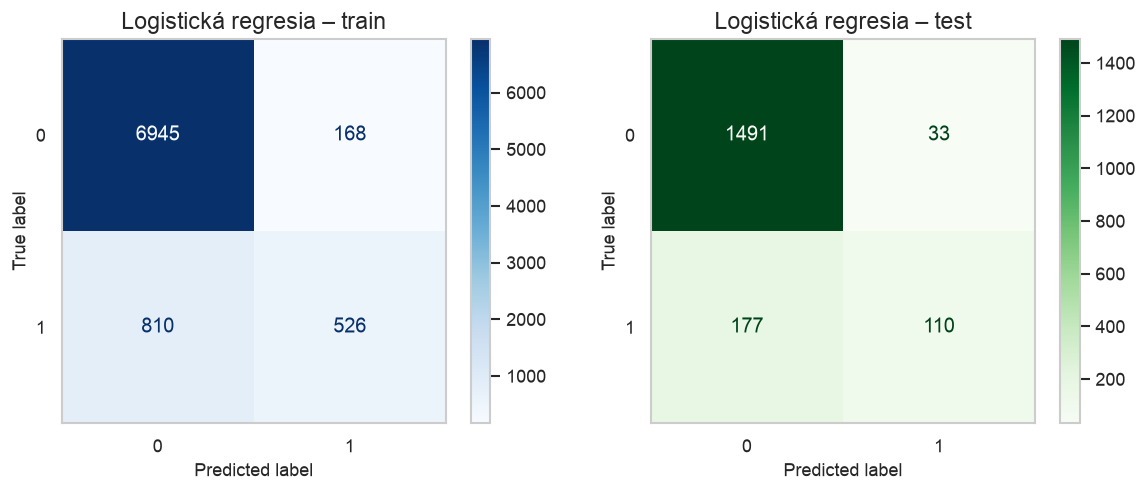

              precision    recall  f1-score   support

  bez nákupu       0.89      0.98      0.93      1524
       nákup       0.77      0.38      0.51       287

    accuracy                           0.88      1811
   macro avg       0.83      0.68      0.72      1811
weighted avg       0.87      0.88      0.87      1811



In [5]:
# Kategorické atribúty prevedieme na binárne one-hot stĺpce.
model_df = pd.get_dummies(df, columns=["Month", "VisitorType"], dtype=int)
# Logické hodnoty musia byť pre model explicitne číselné.
model_df["Weekend"] = model_df["Weekend"].astype(int)
model_df["Revenue"] = model_df["Revenue"].astype(int)

# X obsahuje prediktory; y obsahuje cieľovú premennú, či session skončila nákupom.
X = model_df.drop(columns="Revenue")
y = model_df["Revenue"]

# Najprv vyčleníme 30 % dát a následne ich rozdelíme rovným dielom na validáciu a test.
# Stratifikácia zachováva pomer nákupov vo všetkých množinách.
X_train, X_holdout, y_train, y_holdout = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEED
)
X_val, X_test, y_val, y_test = train_test_split(
    X_holdout, y_holdout, test_size=0.50, stratify=y_holdout, random_state=SEED
)

# Škálovač učíme výhradne na tréningových dátach, aby nevznikol únik informácie.
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)

display(pd.DataFrame({
    "množina": ["train", "validácia", "test"],
    "riadky": [len(y_train), len(y_val), len(y_test)],
    "podiel nákupov (%)": [100 * y_train.mean(), 100 * y_val.mean(), 100 * y_test.mean()],
}).round(2))

# Logistická regresia slúži ako jednoduchý a interpretovateľný baseline.
baseline = LogisticRegression(max_iter=2000, random_state=SEED)
baseline.fit(X_train_s, y_train)

# Pre každú množinu sledujeme aj recall a F1 menšinovej triedy nákupov.
baseline_rows = []
for name, features, target in [("train", X_train_s, y_train),
                               ("validácia", X_val_s, y_val),
                               ("test", X_test_s, y_test)]:
    pred = baseline.predict(features)
    baseline_rows.append({"množina": name, "accuracy": accuracy_score(target, pred),
                          "recall (nákup)": recall_score(target, pred, zero_division=0),
                          "F1 (nákup)": f1_score(target, pred, zero_division=0)})
display(pd.DataFrame(baseline_rows).round(3))

# Konfúzne matice ukážu typy chýb modelu na známych a neznámych dátach.
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, name, features, target, color in [
    (axes[0], "train", X_train_s, y_train, "Blues"),
    (axes[1], "test", X_test_s, y_test, "Greens"),
]:
    ConfusionMatrixDisplay.from_predictions(target, baseline.predict(features), ax=ax, cmap=color)
    ax.set_title(f"Logistická regresia – {name}")
    ax.grid(False)
plt.tight_layout()
plt.show()

# Detailný report je vypísaný pre odloženú testovaciu množinu.
print(classification_report(y_test, baseline.predict(X_test_s),
                            target_names=["bez nákupu", "nákup"], zero_division=0))

In [6]:
# Testujeme, či sa výsledok baseline mení pri rôznych veľkostiach tréningovej množiny.
experiment_rows = []
for test_fraction in [0.10, 0.20, 0.30, 0.50, 0.70]:
    # Každý experiment používa rovnaký seed a stratifikáciu pre férové porovnanie.
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=test_fraction, stratify=y, random_state=SEED
    )

    # Škálovanie sa v každom behu učí nanovo iba z jeho tréningovej časti.
    split_scaler = StandardScaler()
    X_tr_s = split_scaler.fit_transform(X_tr)
    X_te_s = split_scaler.transform(X_te)

    model = LogisticRegression(max_iter=2000, random_state=SEED)
    model.fit(X_tr_s, y_tr)
    test_pred = model.predict(X_te_s)

    # Ukladáme veľkosti množín a metriky potrebné na porovnanie behov.
    experiment_rows.append({
        "test podiel": test_fraction, "train riadky": len(y_tr), "test riadky": len(y_te),
        "test accuracy": accuracy_score(y_te, test_pred),
        "test recall": recall_score(y_te, test_pred, zero_division=0),
        "test F1": f1_score(y_te, test_pred, zero_division=0),
    })

split_experiments = pd.DataFrame(experiment_rows)
display(split_experiments.round(3))

,test podiel,train riadky,test riadky,test accuracy,test recall,test F1
0,0.1,10863,1207,0.883,0.382,0.509
1,0.2,9656,2414,0.886,0.382,0.516
2,0.3,8449,3621,0.884,0.366,0.500
3,0.5,6035,6035,0.884,0.373,0.505
4,0.7,3621,8449,0.883,0.379,0.505


## Prieskumná analýza dát (EDA)

Figure saved to: /Users/polo/workspace/suns-zad-1/results/figures/eda_purchase_rate_by_visitor_type.png
Figure saved to: /Users/polo/workspace/suns-zad-1/results/figures/eda_bounce_vs_exit_rates.png


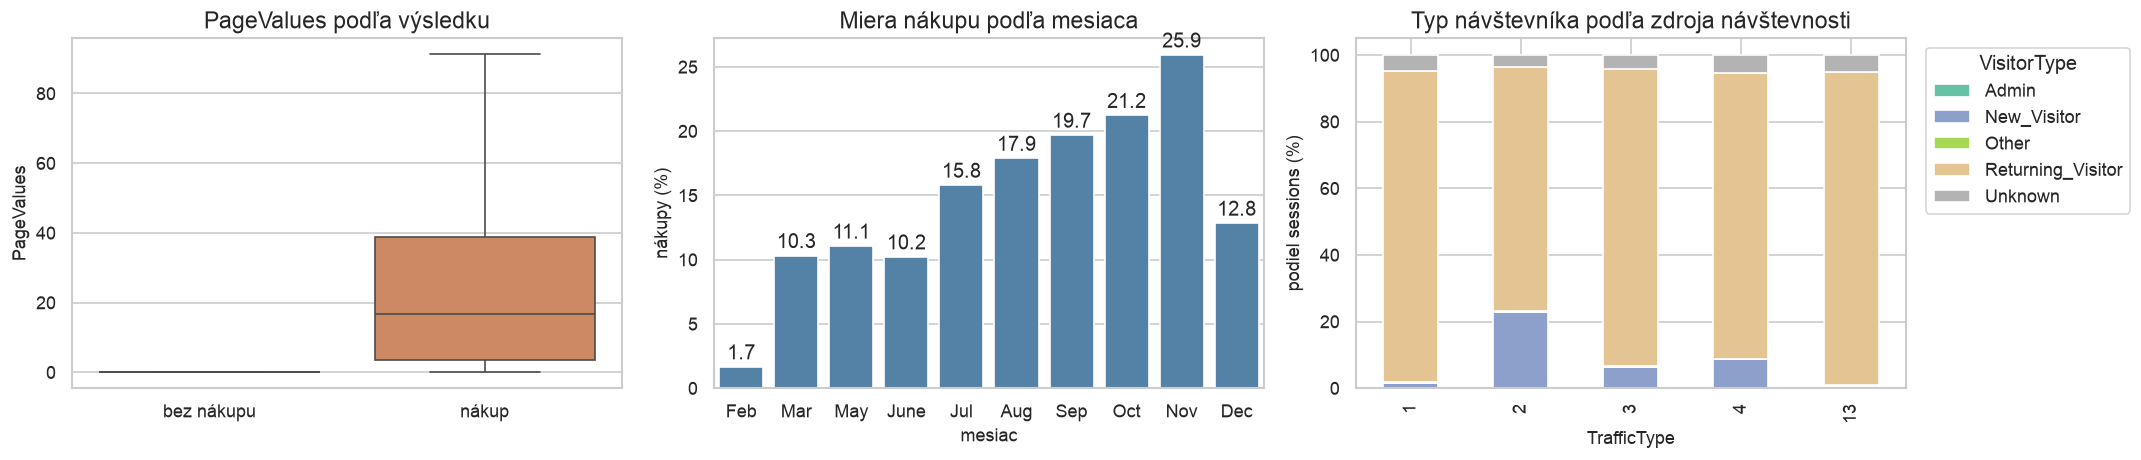

,VisitorType,sessions,purchases,purchase_rate
0,New_Visitor,1593,422,26.49
1,Other,78,16,20.51
2,Returning_Visitor,9912,1471,14.84
3,Admin,1,0,0.00
4,Unknown,486,0,0.00


,relationship,sessions,pearson_correlation,spearman_correlation
0,BounceRates vs ExitRates,12070,0.913,0.601


,sessions,purchase_rate
Month,,
Feb,181,1.66
Mar,1862,10.31
May,3302,11.05
June,284,10.21
Jul,418,15.79
Aug,425,17.88
Sep,437,19.68
Oct,542,21.22
Nov,2936,25.92


VisitorType,Admin,New_Visitor,Other,Returning_Visitor,Unknown
TrafficType,,,,,
1,0.0,1.5,0.2,93.5,4.8
2,0.0,23.0,0.3,73.3,3.5
3,0.0,6.4,0.4,89.2,4.1
4,0.0,8.8,0.0,85.7,5.5
13,0.0,0.7,0.1,94.1,5.0


In [7]:
# Dve samostatné EDA funkcie vytvoria a uložia grafy aj agregované tabuľky.
visitor_summary = plot_purchase_rate_by_visitor_type(df)
bounce_summary = plot_bounce_vs_exit_rates(df)

# Porovnávame PageValues pre sessions s nákupom a bez nákupu.
page_values_plot = df.assign(výsledok=np.where(df["Revenue"], "nákup", "bez nákupu"))
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
sns.boxplot(data=page_values_plot, x="výsledok", y="PageValues",
            order=["bez nákupu", "nákup"], showfliers=False,
            hue="výsledok", legend=False, ax=axes[0])
axes[0].set(title="PageValues podľa výsledku", xlabel="")

# Pri mesiacoch uvádzame relatívnu mieru nákupu, aby počet sessions neskresľoval porovnanie.
month_summary = (
    df.groupby("Month", observed=True)["Revenue"]
    .agg(sessions="size", purchase_rate="mean")
    .assign(purchase_rate=lambda table: 100 * table["purchase_rate"])
    .reindex(["Feb", "Mar", "May", "June", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
    .dropna()
)
sns.barplot(x=month_summary.index, y=month_summary["purchase_rate"],
            color="steelblue", ax=axes[1])
axes[1].set(title="Miera nákupu podľa mesiaca", xlabel="mesiac", ylabel="nákupy (%)")
for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.1f", padding=2)

# Vyberieme päť najčastejších zdrojov a zobrazíme zloženie ich návštevníkov.
top_traffic = df["TrafficType"].value_counts().head(5).index
traffic_mix = pd.crosstab(
    df.loc[df["TrafficType"].isin(top_traffic), "TrafficType"],
    df.loc[df["TrafficType"].isin(top_traffic), "VisitorType"], normalize="index"
).mul(100)
traffic_mix.plot(kind="bar", stacked=True, ax=axes[2], colormap="Set2")
axes[2].set(title="Typ návštevníka podľa zdroja návštevnosti",
            xlabel="TrafficType", ylabel="podiel sessions (%)")
axes[2].legend(title="VisitorType", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# Tabuľky pri grafoch umožňujú presne overiť hodnoty použitých vzťahov.
display(visitor_summary.round(2))
display(bounce_summary.round(4))
display(month_summary.round(2))
display(traffic_mix.round(1))

## Neurónová sieť, pretrénovanie a Early Stopping

In [8]:
# Neurónová sieť pracuje s tensormi typu float32; triedy sú celočíselné indexy 0 a 1.
X_train_t = torch.tensor(X_train_s, dtype=torch.float32)
X_val_t = torch.tensor(X_val_s, dtype=torch.float32)
X_test_t = torch.tensor(X_test_s, dtype=torch.float32)
y_train_t = torch.tensor(y_train.to_numpy(), dtype=torch.long)
y_val_t = torch.tensor(y_val.to_numpy(), dtype=torch.long)
y_test_t = torch.tensor(y_test.to_numpy(), dtype=torch.long)

class PurchaseNet(nn.Module):
    """Plne prepojená sieť s voliteľným dropoutom medzi skrytými vrstvami."""
    def __init__(self, n_features, hidden_layers, dropout=0.0):
        super().__init__()
        layers, previous = [], n_features

        # Každá skrytá vrstva používa lineárnu transformáciu a aktivačnú funkciu ReLU.
        for width in hidden_layers:
            layers.extend([nn.Linear(previous, width), nn.ReLU()])
            if dropout:
                # Dropout počas učenia náhodne vypína časť neurónov a znižuje pretrénovanie.
                layers.append(nn.Dropout(dropout))
            previous = width

        # Výstup má dve logits hodnoty, jednu pre každú triedu Revenue.
        layers.append(nn.Linear(previous, 2))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)

def evaluate_network(network, features, target):
    """Vyhodnotí sieť bez gradientov a vráti metriky spolu s predikciami."""
    network.eval()
    with torch.no_grad():
        prediction = network(features).argmax(dim=1).cpu().numpy()
    truth = target.cpu().numpy()
    return {"accuracy": accuracy_score(truth, prediction),
            "recall": recall_score(truth, prediction, zero_division=0),
            "f1": f1_score(truth, prediction, zero_division=0),
            "pred": prediction}

def train_network(network, epochs, lr, early_stopping=None):
    """Natrénuje sieť a voliteľne obnoví váhy z najlepšej validačnej epochy."""
    optimizer = torch.optim.Adam(network.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()
    history = {"train_loss": [], "val_loss": []}

    # Uchovávame najlepšie váhy, aby sme ich po Early Stopping mohli obnoviť.
    best_weights = copy.deepcopy(network.state_dict())
    best_val_loss, stale_epochs = float("inf"), 0

    for epoch in range(epochs):
        # Tréningový krok: dopredný prechod, gradienty a úprava váh.
        network.train()
        optimizer.zero_grad()
        loss = criterion(network(X_train_t), y_train_t)
        loss.backward()
        optimizer.step()

        # Validačný loss meriame bez gradientov, aby testovacia množina ostala nedotknutá.
        network.eval()
        with torch.no_grad():
            val_loss = criterion(network(X_val_t), y_val_t).item()
        history["train_loss"].append(loss.item())
        history["val_loss"].append(val_loss)

        # Pri zlepšení uložíme aktuálne váhy; inak počítame nezlepšujúce sa epochy.
        if val_loss < best_val_loss - 1e-4:
            best_val_loss, best_weights, stale_epochs = val_loss, copy.deepcopy(network.state_dict()), 0
        else:
            stale_epochs += 1
            if early_stopping is not None and stale_epochs >= early_stopping:
                break

    # Pri Early Stopping sa vrátime k váham s najnižším validačným lossom.
    if early_stopping is not None:
        network.load_state_dict(best_weights)
    return history, epoch + 1, best_val_loss

,množina,accuracy,recall,f1
0,train,0.947,0.892,0.842
1,test,0.885,0.662,0.645


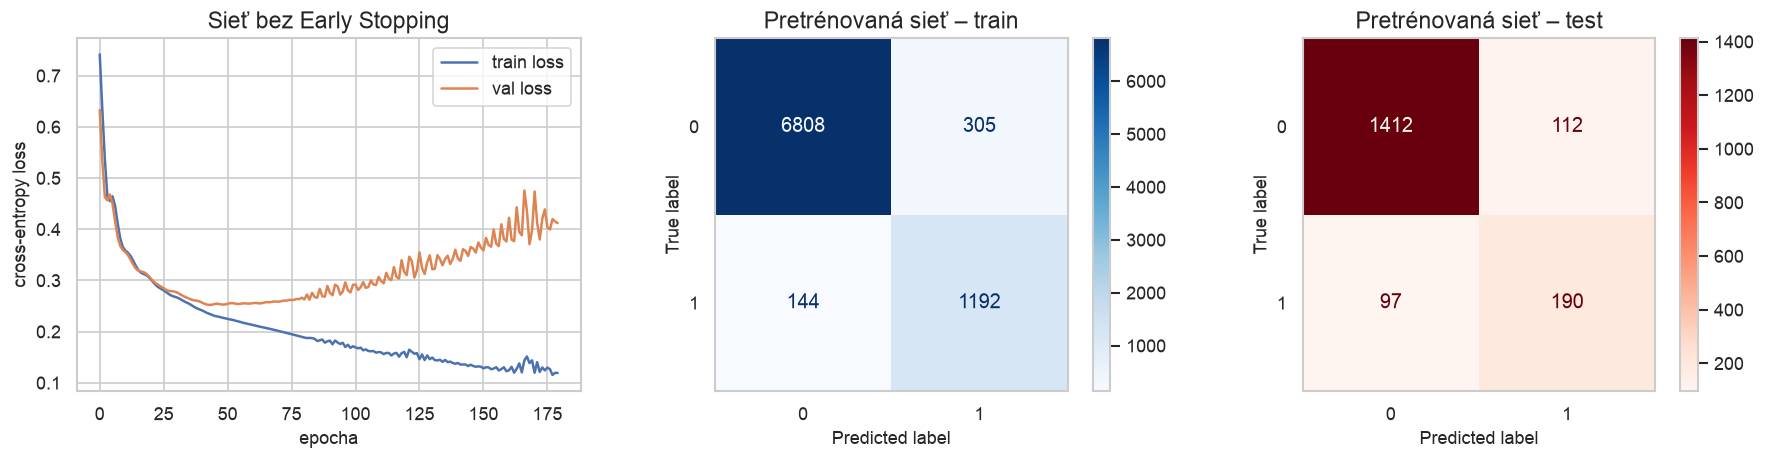

,množina,accuracy,recall,f1
0,train,0.906,0.671,0.693
1,test,0.901,0.613,0.662


Early Stopping po 108 epochách; najlepší validačný loss: 0.2401


In [9]:
# Rovnaký seed umožní reprodukovať demonštráciu pretrénovania.
torch.manual_seed(SEED)

# Veľká sieť bez dropout-u a bez Early Stopping dostane priestor zapamätať si train dáta.
overfit_model = PurchaseNet(X_train_s.shape[1], [256, 128, 64])
overfit_history, overfit_epochs, _ = train_network(overfit_model, epochs=180, lr=0.003)
overfit_train = evaluate_network(overfit_model, X_train_t, y_train_t)
overfit_test = evaluate_network(overfit_model, X_test_t, y_test_t)

# Porovnanie train a test metrík ukazuje rozdiel v schopnosti zovšeobecniť.
display(pd.DataFrame([
    {"množina": "train", **{k: overfit_train[k] for k in ["accuracy", "recall", "f1"]}},
    {"množina": "test", **{k: overfit_test[k] for k in ["accuracy", "recall", "f1"]}},
]).round(3))

# Loss krivky a konfúzne matice názorne dokumentujú pretrénovanie.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(overfit_history["train_loss"], label="train loss")
axes[0].plot(overfit_history["val_loss"], label="val loss")
axes[0].set(title="Sieť bez Early Stopping", xlabel="epocha", ylabel="cross-entropy loss")
axes[0].legend()
for ax, name, target, score, color in [
    (axes[1], "train", y_train, overfit_train, "Blues"),
    (axes[2], "test", y_test, overfit_test, "Reds"),
]:
    ConfusionMatrixDisplay.from_predictions(target, score["pred"], ax=ax, cmap=color)
    ax.set_title(f"Pretrénovaná sieť – {name}")
    ax.grid(False)
plt.tight_layout()
plt.show()

# Druhá sieť je menšia, má dropout a zastavuje sa podľa validačného lossu.
torch.manual_seed(SEED)
early_model = PurchaseNet(X_train_s.shape[1], [128, 64], dropout=0.10)
early_history, early_epochs, best_val_loss = train_network(
    early_model, epochs=250, lr=0.003, early_stopping=18
)
early_train = evaluate_network(early_model, X_train_t, y_train_t)
early_test = evaluate_network(early_model, X_test_t, y_test_t)

# Menší rozdiel medzi train a test metrikami naznačuje lepšie zovšeobecnenie.
display(pd.DataFrame([
    {"množina": "train", **{k: early_train[k] for k in ["accuracy", "recall", "f1"]}},
    {"množina": "test", **{k: early_test[k] for k in ["accuracy", "recall", "f1"]}},
]).round(3))
print(f"Early Stopping po {early_epochs} epochách; najlepší validačný loss: {best_val_loss:.4f}")

,experiment,architektúra,lr,dropout,epochy,train accuracy,train recall,train F1,test accuracy,test recall,test F1
0,3,"[128, 64]",0.005,0.1,88,0.905,0.686,0.696,0.903,0.638,0.675
1,5,"[256, 64]",0.003,0.1,97,0.905,0.676,0.692,0.902,0.620,0.667
2,4,"[64, 64]",0.003,0.1,121,0.904,0.642,0.680,0.901,0.582,0.650
3,2,"[128, 64]",0.001,0.1,160,0.902,0.606,0.662,0.901,0.564,0.643
4,1,"[128, 64]",0.000,0.1,160,0.895,0.505,0.604,0.895,0.484,0.593


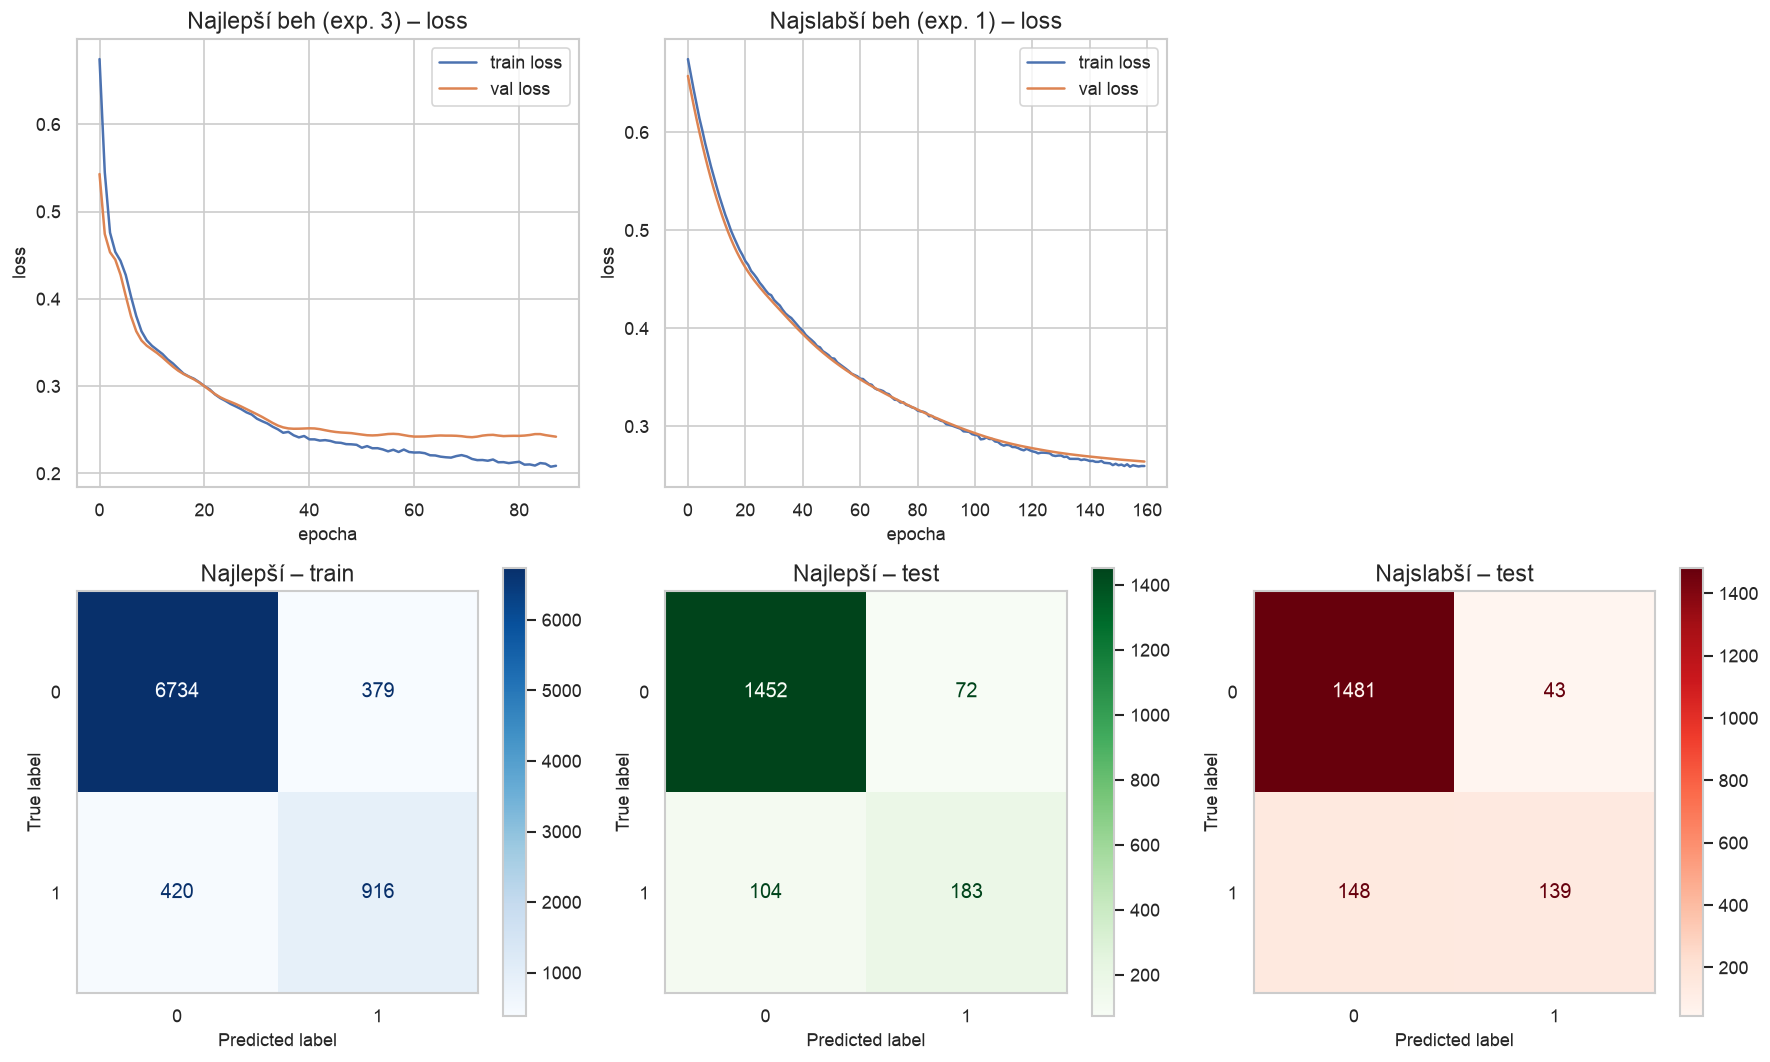

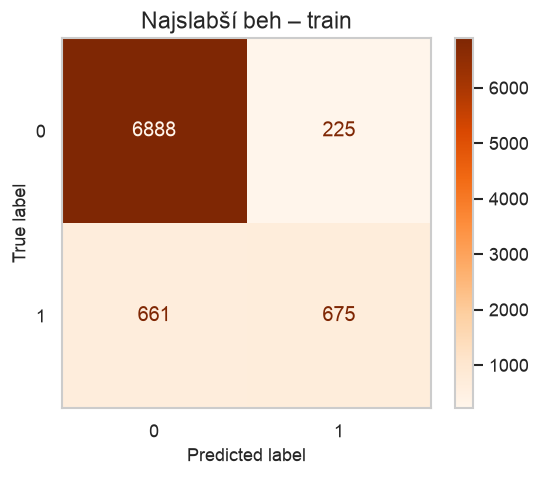

Najlepší beh podľa test F1: experiment 3; najslabší beh: experiment 1.


In [11]:
# Konfigurácie menia learning rate a kapacitu siete; ostatné podmienky zostávajú porovnateľné.
configurations = [
    {"experiment": 1, "architektúra": [128, 64], "lr": 0.0005, "dropout": 0.10},
    {"experiment": 2, "architektúra": [128, 64], "lr": 0.0010, "dropout": 0.10},
    {"experiment": 3, "architektúra": [128, 64], "lr": 0.0050, "dropout": 0.10},
    {"experiment": 4, "architektúra": [64, 64], "lr": 0.0030, "dropout": 0.10},
    {"experiment": 5, "architektúra": [256, 64], "lr": 0.0030, "dropout": 0.10},
]
configuration_rows, configuration_runs = [], {}

for config in configurations:
    # Seed pred každým behom zabezpečí porovnanie bez náhodného rozdielu inicializácie.
    torch.manual_seed(SEED)
    candidate = PurchaseNet(X_train_s.shape[1], config["architektúra"], config["dropout"])
    history, epochs_used, _ = train_network(candidate, epochs=160, lr=config["lr"], early_stopping=16)
    train_score = evaluate_network(candidate, X_train_t, y_train_t)
    test_score = evaluate_network(candidate, X_test_t, y_test_t)

    # Uložíme model, krivky aj metriky na neskorší výber najlepšieho a najslabšieho behu.
    configuration_runs[config["experiment"]] = {
        "model": candidate, "history": history, "train": train_score, "test": test_score,
    }
    configuration_rows.append({
        **config, "epochy": epochs_used,
        "train accuracy": train_score["accuracy"], "train recall": train_score["recall"],
        "train F1": train_score["f1"], "test accuracy": test_score["accuracy"],
        "test recall": test_score["recall"], "test F1": test_score["f1"],
    })

# F1 pre triedu nákupov je hlavné kritérium, preto podľa neho zoradíme tabuľku.
configuration_results = pd.DataFrame(configuration_rows).sort_values(
    "test F1", ascending=False
).reset_index(drop=True)
display(configuration_results.round(3))

# Vyberieme behy s najvyšším a najnižším testovacím F1.
best_experiment = int(configuration_results.iloc[0]["experiment"])
worst_experiment = int(configuration_results.iloc[-1]["experiment"])
best_run, worst_run = configuration_runs[best_experiment], configuration_runs[worst_experiment]

# Horný rad porovnáva krivky lossu; spodný rad porovnáva konfúzne matice.
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, label, experiment, run in [
    (axes[0, 0], "Najlepší", best_experiment, best_run),
    (axes[0, 1], "Najslabší", worst_experiment, worst_run),
]:
    ax.plot(run["history"]["train_loss"], label="train loss")
    ax.plot(run["history"]["val_loss"], label="val loss")
    ax.set(title=f"{label} beh (exp. {experiment}) – loss", xlabel="epocha", ylabel="loss")
    ax.legend()
axes[0, 2].axis("off")

for ax, label, target, score, color in [
    (axes[1, 0], "Najlepší – train", y_train, best_run["train"], "Blues"),
    (axes[1, 1], "Najlepší – test", y_test, best_run["test"], "Greens"),
    (axes[1, 2], "Najslabší – test", y_test, worst_run["test"], "Reds"),
]:
    ConfusionMatrixDisplay.from_predictions(target, score["pred"], ax=ax, cmap=color)
    ax.set_title(label)
    ax.grid(False)
plt.tight_layout()
plt.show()

# Posledná samostatná matica dopĺňa trénovaciu množinu najslabšieho behu.
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_train, worst_run["train"]["pred"], ax=ax, cmap="Oranges")
ax.set_title("Najslabší beh – train")
ax.grid(False)
plt.show()
print(f"Najlepší beh podľa test F1: experiment {best_experiment}; najslabší beh: experiment {worst_experiment}.")